# Combining the methods for cuts

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

plt.rcParams['figure.figsize'] = (8, 6)
plt.rcParams['font.size'] = 25
plt.rcParams['axes.labelsize'] = 25
plt.rcParams['xtick.labelsize'] = 25
plt.rcParams['ytick.labelsize'] = 25
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['font.family'] = 'STIXGeneral'

from glob import glob

In [2]:
def calculate_PAO_spectrum_old(e_eV):
    """
    Calculate the CR flux measured by PAO in 10 ** 17 eV < E < 10 ** 20 eV
    with the SD-750 and SD-1500.
    The formula of the spectrum is Equation (13) of
    Abreu et al., Eur. Phys. J. C 81, 966 (2021)
    (https://doi.org/10.1140/epjc/s10052-021-09700-w)
    """


    j_0 = 1.309e-18 # km^-2 yr^-1 sr^-1 eV^-1
    e_0 = 10 ** 18.5 # eV
    omega_01, omega_12, omega_23, omega_34 = 0.43, 0.05, 0.05, 0.05
    g_0, g_1, g_2, g_3, g_4 = 2.64, 3.298, 2.52, 3.08, 5.2
    e_01, e_12, e_23, e_34 = 1.24e17, 4.9e18, 1.4e19, 4.7e19 # eV

    j = j_0 * (e_eV/e_0) ** (-g_0) \
            * (1 + (e_eV/e_01) ** (1/omega_01)) ** ((g_0-g_1) * omega_01) \
            * (1 + (e_eV/e_12) ** (1/omega_12)) ** ((g_1-g_2) * omega_12) \
            * (1 + (e_eV/e_23) ** (1/omega_23)) ** ((g_2-g_3) * omega_23) \
            * (1 + (e_eV/e_34) ** (1/omega_34)) ** ((g_3-g_4) * omega_34) \
            / (1 + (e_0/e_01)  ** (1/omega_01)) ** ((g_0-g_1) * omega_01) \
            / (1 + (e_0/e_12)  ** (1/omega_12)) ** ((g_1-g_2) * omega_12) \
            / (1 + (e_0/e_23)  ** (1/omega_23)) ** ((g_2-g_3) * omega_23) \
            / (1 + (e_0/e_34)  ** (1/omega_34)) ** ((g_3-g_4) * omega_34)

    return j

def calculate_PAO_spectrum(e_eV):
    """
    Calculate the CR flux measured by PAO in 10 ** 17 eV < E < 10 ** 20 eV
    with the SD-750 and SD-1500.
    The formula of the spectrum is Equation (2) of
    Ravignani, PoS(ICRC2025)370
    (https://arxiv.org/abs/2507.08573)
    """

    e_EeV = e_eV / 1e18 # convert eV to EeV

    j_0 = 1.269e-18 # km^-2 yr^-1 sr^-1 eV^-1
    e_0 = 10 ** 0.5 # EeV
    w_1, w_2, w_3 = 0.5, 0.05, 0.05
    g_0, g_1, g_2, g_3, g_4 = 2.64, 3.26, 2.51, 2.99, 5.4
    e_1, e_2, e_3 = 5.1, 13, 48 # EeV

    j = j_0 * (e_EeV/e_0) ** (-g_0) \
            * (1 + (e_EeV/e_1) ** (1/w_1)) ** ((g_1-g_2) * w_1) \
            * (1 + (e_EeV/e_2) ** (1/w_2)) ** ((g_2-g_3) * w_2) \
            * (1 + (e_EeV/e_3) ** (1/w_3)) ** ((g_3-g_4) * w_3) \
            / (1 + (e_0/e_1)  ** (1/w_1)) ** ((g_1-g_2) * w_1) \
            / (1 + (e_0/e_2)  ** (1/w_2)) ** ((g_2-g_3) * w_2) \
            / (1 + (e_0/e_3)  ** (1/w_3)) ** ((g_3-g_4) * w_3)

    return j

## Extract data

In [3]:
parasite_chi2_PWF_RUN = np.load(f"/sps/grand/jlavoisier/code/quantification/check_data/data/chi2_PWF_parasites.npy",
                    allow_pickle=True
                    ).item()
parasite_chi2_SWF_RUN = np.load(f"/sps/grand/jlavoisier/code/quantification/check_data/data/chi2_SWF_parasites.npy",
                    allow_pickle=True
                    ).item()
parasite_chi2_ADF_RUN = np.load(f"/sps/grand/jlavoisier/code/quantification/check_data/data/chi2_ADF_parasites.npy",
                    allow_pickle=True
                    ).item()
parasite_polarization_RUN = np.load(f"/sps/grand/jlavoisier/code/quantification/check_data/data/polar_parasites.npy",
                    allow_pickle=True
                    ).item()
parasite_theta_RUN = np.load(f"/sps/grand/jlavoisier/code/quantification/check_data/data/theta_parasites.npy",
                    allow_pickle=True
                    ).item()
parasite_phi_RUN = np.load(f"/sps/grand/jlavoisier/code/quantification/check_data/data/phi_parasites.npy",
                    allow_pickle=True
                    ).item()
parasite_time_RUN = np.load(f"/sps/grand/jlavoisier/code/quantification/check_data/data/time_parasites.npy",
                    allow_pickle=True
                    ).item()

RUN = np.array(list(parasite_chi2_PWF_RUN.keys()))

parasite_chi2_PWF = np.array([])
parasite_chi2_SWF = np.array([])
parasite_chi2_ADF = np.array([])
parasite_polarization = np.array([])
parasite_theta = np.array([])
parasite_phi = np.array([])
parasite_time = np.array([])

for run in RUN:
    parasite_chi2_PWF = np.concatenate((parasite_chi2_PWF, parasite_chi2_PWF_RUN[run]))
    parasite_chi2_SWF = np.concatenate((parasite_chi2_SWF, parasite_chi2_SWF_RUN[run]))
    parasite_chi2_ADF = np.concatenate((parasite_chi2_ADF, parasite_chi2_ADF_RUN[run]))
    parasite_polarization = np.concatenate((parasite_polarization, parasite_polarization_RUN[run]))
    parasite_theta = np.concatenate((parasite_theta, parasite_theta_RUN[run]))
    parasite_phi = np.concatenate((parasite_phi, parasite_phi_RUN[run]))
    parasite_time = np.concatenate((parasite_time, parasite_time_RUN[run]))

In [4]:
pass_cluster = np.load(f"/sps/grand/jlavoisier/code/quantification/cluster_neighbour_quant/cluster_results/cluster_pass_5s_10deg.npy",
                           allow_pickle=True
                        ).item()

mask_parasite_cluster = np.array([])
for run in RUN:
    mask_parasite_cluster = np.concatenate((mask_parasite_cluster, pass_cluster[run][:len(parasite_theta_RUN[run])]))

## Extract sims

In [5]:
path = f"/sps/grand/jlavoisier/code/quantification/check_sims/out_files/simsGP300NJ_theta_n_ant_energy.npy"

file_sims = np.load(path)

theta_tot = file_sims[0]
phi_tot = file_sims[1]
n_ant_trig_tot = file_sims[2]
energy_tot = file_sims[3]

theta = theta_tot[n_ant_trig_tot >= 5]
phi = phi_tot[n_ant_trig_tot >= 5]
energy = energy_tot[n_ant_trig_tot >= 5]

In [6]:
# chi2 PWF
sim_path_PWF = sorted(glob("/sps/grand/jlavoisier/code/quantification/SWF_quant/out_files/batch/ZHAiReS/AN*PWF*"))
sims_chi2_PWF = np.array([])

for i in range(len(sim_path_PWF)):
    file_sims = np.load(sim_path_PWF[i])
    print("Number of simulated events in file ", sim_path_PWF[i], " : ", len(file_sims[0]))
    sims_chi2_PWF = np.append(sims_chi2_PWF, file_sims[1])

# chi2 SWF
sim_path_SWF = sorted(glob("/sps/grand/jlavoisier/code/quantification/SWF_quant/out_files/batch/ZHAiReS/AN_*SWF*"))
sims_chi2_SWF = np.array([])

for i in range(len(sim_path_SWF)):
    file_sims = np.load(sim_path_SWF[i])
    print("Number of simulated events in file ", sim_path_SWF[i], " : ", len(file_sims[0]))
    sims_chi2_SWF = np.append(sims_chi2_SWF, file_sims[1])

# chi2 ADF
sim_path_ADF = sorted(glob("/sps/grand/jlavoisier/code/quantification/ADF_quant/out_files/batch/AN_*"))
sims_chi2_ADF = np.array([])

for i in range(len(sim_path_ADF)):
    file_sims = np.load(sim_path_ADF[i])
    print("Number of simulated events in file ", sim_path_ADF[i], " : ", len(file_sims[0]))
    sims_chi2_ADF = np.append(sims_chi2_ADF, file_sims[1])

# polarization
sims_polarization = np.load("/sps/grand/jlavoisier/code/quantification/polarization_cut/out_files/ZHAiReSGP300AN_polar.npy")[0]
sims_info = np.load("/sps/grand/jlavoisier/code/quantification/polarization_cut/out_files/ZHAiReSGP300AN_event_info.npy")

sims_n_ant_trig = sims_info[0]
sims_polar_per_event = np.zeros(len(sims_n_ant_trig))

for i in range(len(sims_n_ant_trig)):
    polar_event_i = sims_polarization[int(np.sum(sims_n_ant_trig[:i])):int(np.sum(sims_n_ant_trig[:i+1]))]
    sims_polar_per_event[i] = np.median(polar_event_i[polar_event_i < 2])


Number of simulated events in file  /sps/grand/jlavoisier/code/quantification/SWF_quant/out_files/batch/ZHAiReS/AN_0001_chi2_PWF_n_ant.npy  :  0
Number of simulated events in file  /sps/grand/jlavoisier/code/quantification/SWF_quant/out_files/batch/ZHAiReS/AN_0002_chi2_PWF_n_ant.npy  :  0
Number of simulated events in file  /sps/grand/jlavoisier/code/quantification/SWF_quant/out_files/batch/ZHAiReS/AN_0003_chi2_PWF_n_ant.npy  :  0
Number of simulated events in file  /sps/grand/jlavoisier/code/quantification/SWF_quant/out_files/batch/ZHAiReS/AN_0004_chi2_PWF_n_ant.npy  :  146
Number of simulated events in file  /sps/grand/jlavoisier/code/quantification/SWF_quant/out_files/batch/ZHAiReS/AN_0005_chi2_PWF_n_ant.npy  :  456
Number of simulated events in file  /sps/grand/jlavoisier/code/quantification/SWF_quant/out_files/batch/ZHAiReS/AN_0006_chi2_PWF_n_ant.npy  :  691
Number of simulated events in file  /sps/grand/jlavoisier/code/quantification/SWF_quant/out_files/batch/ZHAiReS/AN_0007_chi2

/pbs/home/j/jlavoisier/.local/lib/python3.9/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/pbs/home/j/jlavoisier/.local/lib/python3.9/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [7]:
# weights

# weights_energy_events = np.zeros(len(energy))
# for i in range(len(energy)):
#     weights_energy_events[i] = calculate_PAO_spectrum(energy[i] * 1e9) # The weight for the energy bin

weights_energy_events = calculate_PAO_spectrum(energy * 1e9)
weights_zenith_events = np.sin(theta * np.pi / 180) * np.cos(theta * np.pi / 180) # The weight for the zenith bin
weights_events = weights_energy_events * weights_zenith_events


weights_distrib_theta = 1 / np.log10(1/np.cos(theta * np.pi / 180)) # The weight for the zenith bin in the distribution
weights_distrib_energy = energy * 1e9 # The weight for the energy bin in the distribution
weights_events = weights_events * weights_distrib_theta * weights_distrib_energy

## Cut parameters

In [8]:
chi2_PWF_threshold = 1.42e3
chi2_SWF_threshold = 2.17e3
chi2_ADF_threshold = 72.1
polarization_threshold = 0.23

## Cut efficiency

In [9]:
mask_parasite_chi2_PWF = parasite_chi2_PWF < chi2_PWF_threshold
mask_parasite_chi2_SWF = parasite_chi2_SWF < chi2_SWF_threshold
mask_parasite_chi2_ADF = parasite_chi2_ADF < chi2_ADF_threshold
mask_parasite_polarization = parasite_polarization < polarization_threshold

mask_parasite_combined = mask_parasite_chi2_PWF & mask_parasite_chi2_SWF & mask_parasite_chi2_ADF & mask_parasite_polarization & np.bool(mask_parasite_cluster)

print(f"Number of surviving parasites: {np.sum(mask_parasite_combined)}")
print(f"Cut efficiency: {100 - 100*np.sum(mask_parasite_combined)/len(mask_parasite_combined)}")

print("--------------------------")
# without low zenith events and mine direction events

mask_zenith = (parasite_theta*180/np.pi >= 60) & (parasite_theta*180/np.pi <= 88)
mask_mine = (parasite_phi*180/np.pi >= 20) & (parasite_phi*180/np.pi <= 40)

mask_parasite_combined_2 = mask_parasite_combined & mask_zenith & ~mask_mine

print("Without low zenith events and mine direction events:")
print(f"Number of surviving parasites: {np.sum(mask_parasite_combined_2)}")
print(f"Cut efficiency: {100 - 100*np.sum(mask_parasite_combined_2)/len(mask_parasite_combined_2)}")

Number of surviving parasites: 296309
Cut efficiency: 94.5684545495373
--------------------------
Without low zenith events and mine direction events:
Number of surviving parasites: 134390
Cut efficiency: 97.53653991918003


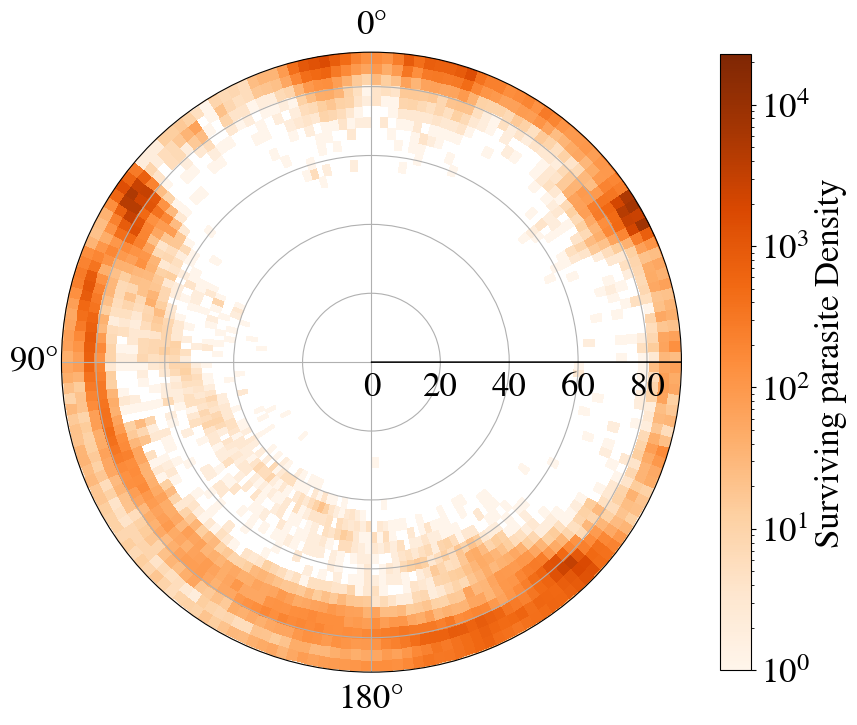

In [10]:
surv_parasite_theta = parasite_theta[mask_parasite_combined]
surv_parasite_phi = parasite_phi[mask_parasite_combined]

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='polar')
ax.set_theta_zero_location("N")

hist = ax.hist2d(surv_parasite_phi-np.pi/2,
                surv_parasite_theta*180/np.pi,
                bins=[180, 45],
                cmap='Oranges',
                # alpha=0.7,
                label='Surviving parasites',
                norm=mpl.colors.LogNorm(),
                rasterized=True
                )


plt.colorbar(hist[3], 
             ax=ax, 
             label='Surviving parasite Density',
            #  pad=0.08,
             shrink=0.8
             )
ax.set_ylim(0, 90)

ax.tick_params(axis="x",
               pad=9,
               )

# plt.legend(fontsize=25,
#            loc='center left', 
#            bbox_to_anchor=(-0.15, -0.15, 1, 0.1),
#            ncol=2,
#            columnspacing=1,
#            handletextpad=0.4,
#            handlelength=1,
#            frameon=False
#            )

plt.savefig(f"/sps/grand/jlavoisier/code/quantification/0_plots_article/combined_polar_distrib_{len(surv_parasite_theta)}-cutparasites.pdf",
            format='pdf', 
            dpi=300, 
            bbox_inches = "tight"
            )


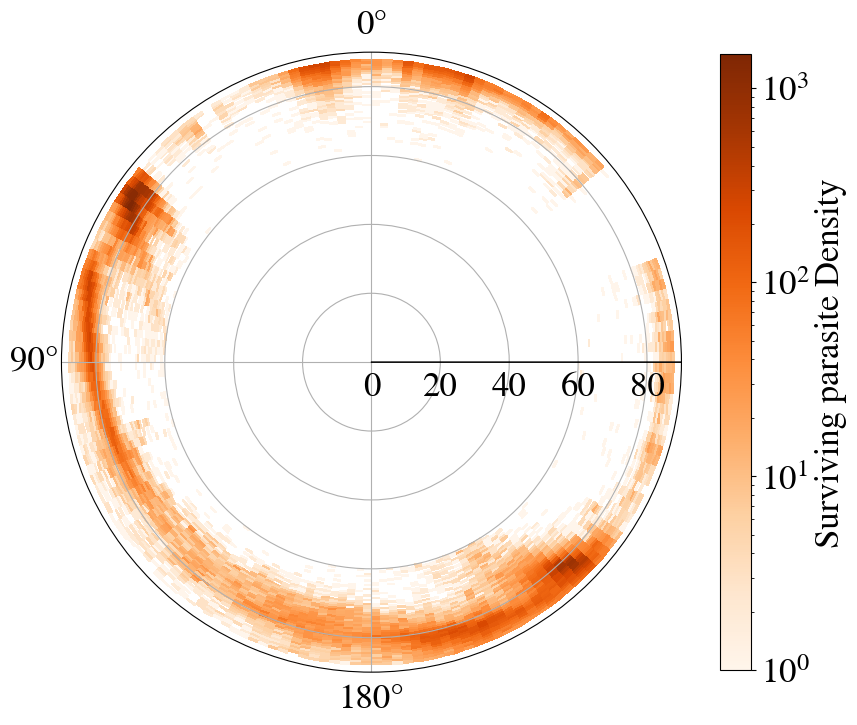

In [11]:
surv_parasite_theta = parasite_theta[mask_parasite_combined_2]
surv_parasite_phi = parasite_phi[mask_parasite_combined_2]

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='polar')
ax.set_theta_zero_location("N")

hist = ax.hist2d(surv_parasite_phi-np.pi/2,
                surv_parasite_theta*180/np.pi,
                bins=[180, 45],
                cmap='Oranges',
                # alpha=0.7,
                label='Surviving parasites',
                norm=mpl.colors.LogNorm(),
                rasterized=True
                )


plt.colorbar(hist[3], 
             ax=ax, 
             label='Surviving parasite Density',
            #  pad=0.08,
             shrink=0.8
             )
ax.set_ylim(0, 90)

ax.tick_params(axis="x",
               pad=9,
               )

# plt.legend(fontsize=25,
#            loc='center left', 
#            bbox_to_anchor=(-0.15, -0.15, 1, 0.1),
#            ncol=2,
#            columnspacing=1,
#            handletextpad=0.4,
#            handlelength=1,
#            frameon=False
#            )

# plt.savefig(f"/sps/grand/jlavoisier/code/quantification/0_plots_article/combined_polar_distrib_{len(surv_parasite_theta)}-cutparasites.pdf",
#             format='pdf', 
#             dpi=300, 
#             bbox_inches = "tight"
#             )


## Loss rate

Couldn't associate the loss rate with the cluster cut, as it was estimated on another data sample. Thus, we can only estimate the cut efficiency, which is the fraction of events that pass the cuts. The loss rate is the fraction of events that are lost due to the cuts.

In [12]:
mask_CR_chi2_PWF = sims_chi2_PWF < chi2_PWF_threshold
mask_CR_chi2_SWF = sims_chi2_SWF < chi2_SWF_threshold
mask_CR_chi2_ADF = sims_chi2_ADF < chi2_ADF_threshold
mask_CR_polarization = sims_polar_per_event < polarization_threshold

mask_CR_combined = mask_CR_chi2_PWF & mask_CR_chi2_SWF & mask_CR_chi2_ADF & mask_CR_polarization

print(f"Number of surviving CR: {np.sum(mask_CR_combined)}")
print(f"CR loss rate: {(1-np.sum(weights_events[mask_CR_combined])/np.sum(weights_events))*100} %")

Number of surviving CR: 3417
CR loss rate: 3.0639223832588436 %


# Zenith combination

## Apply cluster cut on filetered data

In [13]:
mask_CR_zenith_to_keep = (theta*180/np.pi >= 60) & (theta*180/np.pi <= 88)
mask_CR_mine_to_get_rid = (phi*180/np.pi >= 20) & (phi*180/np.pi <= 40)

In [32]:
mockCR_time = np.load(f"/sps/grand/jlavoisier/code/quantification/cluster_neighbour_quant/mockCR_dataset/time_RUNs.npy",
                    allow_pickle=True
                    ).item()
mockCR_phi = np.load(f"/sps/grand/jlavoisier/code/quantification/cluster_neighbour_quant/mockCR_dataset/phi_RUNs.npy",
                    allow_pickle=True
                    ).item()
mockCR_theta = np.load(f"/sps/grand/jlavoisier/code/quantification/cluster_neighbour_quant/mockCR_dataset/theta_RUNs.npy",
                    allow_pickle=True
                    ).item()


mockCR_selected_time_RUN = {}
mockCR_selected_theta_RUN = {}
mockCR_selected_phi_RUN = {}

parasite_selected_time_RUN = {}
parasite_selected_theta_RUN = {}
parasite_selected_phi_RUN = {}

for run in RUN:
    mask_zenith_RUN = (parasite_theta_RUN[run]*180/np.pi >= 60) & (parasite_theta_RUN[run]*180/np.pi <= 88)
    mask_mine_RUN = (parasite_phi_RUN[run]*180/np.pi >= 20) & (parasite_phi_RUN[run]*180/np.pi <= 40)
    parasite_selected_time_RUN[run] = parasite_time_RUN[run][mask_zenith_RUN & ~mask_mine_RUN]
    parasite_selected_theta_RUN[run] = parasite_theta_RUN[run][mask_zenith_RUN & ~mask_mine_RUN]
    parasite_selected_phi_RUN[run] = parasite_phi_RUN[run][mask_zenith_RUN & ~mask_mine_RUN]

    print(run, len(parasite_time_RUN[run]), len(parasite_selected_time_RUN[run]))

    mask_mockCR_zenith_RUN = (mockCR_theta[run] >= 60) & (mockCR_theta[run] <= 88)
    mask_mockCR_mine_RUN = (mockCR_phi[run] >= 20) & (mockCR_phi[run] <= 40)
    mockCR_selected_time_RUN[run] = mockCR_time[run][mask_mockCR_zenith_RUN & ~mask_mockCR_mine_RUN]
    mockCR_selected_theta_RUN[run] = mockCR_theta[run][mask_mockCR_zenith_RUN & ~mask_mockCR_mine_RUN]
    mockCR_selected_phi_RUN[run] = mockCR_phi[run][mask_mockCR_zenith_RUN & ~mask_mockCR_mine_RUN]



# mask_parasite_zenith_to_keep = (parasite_theta*180/np.pi >= 60) & (parasite_theta*180/np.pi <= 88)
# mask_parasite_mine_to_get_rid = (parasite_phi*180/np.pi >= 20) & (parasite_phi*180/np.pi <= 40)

# parasite_selected_time = parasite_time[mask_parasite_zenith_to_keep & ~mask_parasite_mine_to_get_rid]
# parasite_selected_theta = parasite_theta[mask_parasite_zenith_to_keep & ~mask_parasite_mine_to_get_rid]
# parasite_selected_phi = parasite_phi[mask_parasite_zenith_to_keep & ~mask_parasite_mine_to_get_rid]

RUN10122 3628 3028
RUN10123 23 18
RUN10124 49 19
RUN10127 1242113 317266
RUN10128 281515 210080
RUN10129 108528 33099
RUN10130 34169 7058
RUN10132 1814122 836960
RUN10143 1078594 42926
RUN10141 308537 19582
RUN10136 5681 214
RUN10131 33455 18379
RUN10135 11 6
RUN10133 14784 4436
RUN10137 1 0
RUN10146 210683 148505
RUN10145 317483 11423
RUN10179 244 28
RUN10176 0 0
RUN10177 0 0
RUN10180 0 0
RUN10178 1715 293


In [34]:
loop_time_window = np.logspace(np.log10(1), np.log10(1e3), 45)
loop_angle_window = np.arange(2, 47, 2)

In [35]:
# values associated to 79% cut efficiency and ~3% loss rate on all data
delta_t_lim = 2 # in seconds
delta_vartheta_lim = 10 # in degrees



cluster_selected_pass = {}
events_selected_per_run = {}
CR_selected_per_run = {}

consecutive_events_cluster_or = np.array([])

total_events = 0
total_CR = 0

count_parasites = 0
count_CR = 0


count_parasites_or = np.zeros((len(loop_time_window), len(loop_angle_window)))
count_CR_or = np.zeros((len(loop_time_window), len(loop_angle_window)))


for run in RUN:
    parasite_time_s = parasite_selected_time_RUN[run]

    if len(parasite_time_s) < 2:
        cluster_selected_pass[run]= np.ones(len(parasite_time_s), dtype=bool)
        continue

    print(f"RUN {run} with {len(parasite_time_s)} parasites and {len(mockCR_time[run])} mock CR events")
    time_event = np.array(parasite_time_s) - np.min(parasite_time_s)
    theta_event = np.array(parasite_selected_theta_RUN[run])
    phi_event = np.array(parasite_selected_phi_RUN[run])

    # select only the events in the zenith range and not in the mine direction
    mask_zenith = (theta_event*180/np.pi >= 60) & (theta_event*180/np.pi <= 88)
    mask_mine = (phi_event*180/np.pi >= 20) & (phi_event*180/np.pi <= 40)

    events_selected_per_run[run] = mask_zenith & ~mask_mine
    time_event = time_event[events_selected_per_run[run]]
    theta_event = theta_event[events_selected_per_run[run]]
    phi_event = phi_event[events_selected_per_run[run]]

    indicator = np.zeros(len(time_event))


    # extract CR
    time_event = np.append(time_event, np.floor(np.array(mockCR_selected_time_RUN[run])))
    theta_event = np.append(theta_event, np.array(mockCR_selected_theta_RUN[run]))
    phi_event = np.append(phi_event, np.array(mockCR_selected_phi_RUN[run]))
    
    indicator = np.append(indicator, np.ones(len(mockCR_selected_time_RUN[run])))


    # sort wrt time
    sort = np.argsort(time_event)
    time_event = time_event[sort]
    theta_event = theta_event[sort]
    phi_event = phi_event[sort]

    indicator = indicator[sort]

    # count the number of events and CR events
    total_events += len(time_event)
    total_CR += len(mockCR_time[run])


    consecutive_mask = np.ones(len(time_event)-1, dtype=bool)

    time_between_consecutive = np.abs(time_event[1:]-time_event[:-1])
    theta_between_consecutive = np.abs(theta_event[1:]-theta_event[:-1])
    phi_between_consecutive = np.abs((phi_event[1:]-phi_event[:-1]+np.pi) % (2*np.pi) - np.pi)


    # consecutive_mask[np.all([time_between_consecutive < delta_t_lim, 
    #                             theta_between_consecutive < delta_vartheta_lim, 
    #                             phi_between_consecutive < delta_vartheta_lim], 
    #                             axis=0)] = False

    # test_cluster_neighbours_or = np.ones(len(time_event), dtype=bool) # False if both neighbour is in a cluster

    # for k in range(len(time_event)):
    #     if k == 0:
    #         test_cluster_neighbours_or[k] = consecutive_mask[k]
    #     elif k == len(time_event)-1:
    #         test_cluster_neighbours_or[k] = consecutive_mask[k-1]
    #     else:
    #         test_cluster_neighbours_or[k] = consecutive_mask[k] or consecutive_mask[k-1] 

    # count_parasites += np.sum(test_cluster_neighbours_or[indicator==0])
    # count_CR += np.sum(test_cluster_neighbours_or[indicator==1])

    for i in range(len(loop_time_window)):
        for j in range(len(loop_angle_window)):
            consecutive_mask[np.all([time_between_consecutive < loop_time_window[i], 
                                        theta_between_consecutive < loop_angle_window[j], 
                                        phi_between_consecutive < loop_angle_window[j]], 
                                        axis=0)] = False

            test_cluster_neighbours_or = np.ones(len(time_event), dtype=bool) # False if both neighbour is in a cluster

            for k in range(len(time_event)):
                if k == 0:
                    test_cluster_neighbours_or[k] = consecutive_mask[k]
                elif k == len(time_event)-1:
                    test_cluster_neighbours_or[k] = consecutive_mask[k-1]
                else:
                    test_cluster_neighbours_or[k] = consecutive_mask[k] or consecutive_mask[k-1] 

            count_parasites_or[i, j] += np.sum(test_cluster_neighbours_or[indicator==0])
            count_CR_or[i, j] += np.sum(test_cluster_neighbours_or[indicator==1])


    cluster_selected_pass[run] = test_cluster_neighbours_or[np.argsort(sort)]#[:len(parasite_time_s[run])] # sort back to original order

    

# cut_efficiency = 100 - count_parasites/total_events*100
# loss_CR = 100 - count_CR/total_CR*100

# print(f"Cut efficiency: {cut_efficiency} %")
# print(f"Loss of CR: {loss_CR} % : {count_CR}/{total_CR}")



RUN RUN10122 with 3028 parasites and 0 mock CR events
RUN RUN10123 with 18 parasites and 0 mock CR events
RUN RUN10124 with 19 parasites and 0 mock CR events
RUN RUN10127 with 317266 parasites and 51 mock CR events
RUN RUN10128 with 210080 parasites and 18 mock CR events
RUN RUN10129 with 33099 parasites and 107 mock CR events
RUN RUN10130 with 7058 parasites and 111 mock CR events
RUN RUN10132 with 836960 parasites and 64 mock CR events
RUN RUN10143 with 42926 parasites and 1 mock CR events
RUN RUN10141 with 19582 parasites and 13 mock CR events
RUN RUN10136 with 214 parasites and 0 mock CR events
RUN RUN10131 with 18379 parasites and 63 mock CR events
RUN RUN10135 with 6 parasites and 0 mock CR events
RUN RUN10133 with 4436 parasites and 11 mock CR events
RUN RUN10146 with 148505 parasites and 9 mock CR events
RUN RUN10145 with 11423 parasites and 2 mock CR events
RUN RUN10179 with 28 parasites and 28 mock CR events
RUN RUN10178 with 293 parasites and 0 mock CR events
Cut efficiency:

In [36]:

cut_efficiency_grid_or = np.zeros((len(loop_time_window), len(loop_angle_window)))
loss_CR_grid_or = np.zeros((len(loop_time_window), len(loop_angle_window)))

for i in range(len(loop_time_window)):
        for j in range(len(loop_angle_window)):
            cut_efficiency_grid_or[i, j] = 100 - count_parasites_or[i, j]/total_events*100
            loss_CR_grid_or[i, j] = 100 - count_CR_or[i, j]/total_CR*100

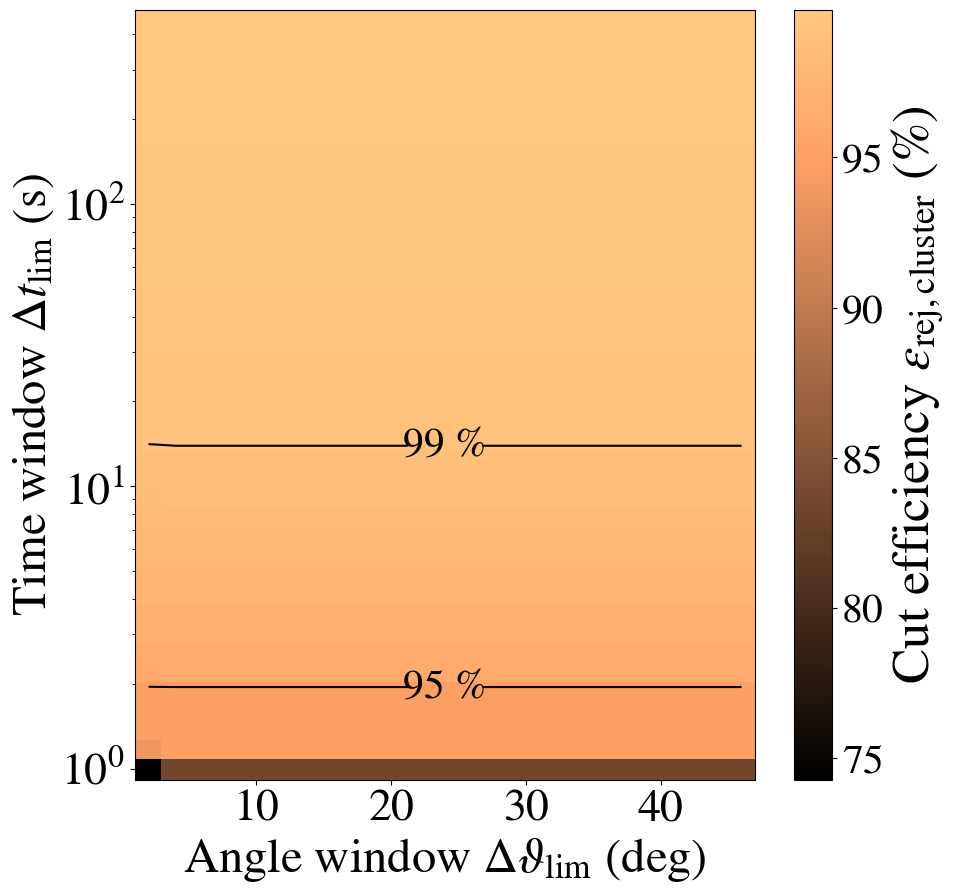

In [ ]:
Xmin = 1
index_plot_min = np.argmin(np.abs(loop_time_window - Xmin))
Xmax = 500
index_plot_max = np.argmin(np.abs(loop_time_window - Xmax))


def fmt(x):
    s = f"{x:.1f}"
    if s.endswith("0"):
        s = f"{x:.0f}"
    return rf"{s} \%" if plt.rcParams["text.usetex"] else f"{s} %"

plt.figure(figsize=(10, 10))
# Plot using pcolor

X0, Y0 = np.meshgrid(loop_angle_window,#*180/np.pi, 
                     loop_time_window[index_plot_min:index_plot_max])

im0 = plt.pcolor(X0,
                   Y0,
                   cut_efficiency_grid_or[index_plot_min:index_plot_max, :], 
                   cmap='copper', 
                #    aspect='auto',
                   # origin='lower',
                    rasterized=True,
                   norm=mpl.colors.Normalize(
                                     vmin=cut_efficiency_grid_or[index_plot_min:index_plot_max, :].min(), 
                                    #  vmin=0,
                                    #  vmax=100,
                                     vmax= cut_efficiency_grid_or[index_plot_min:index_plot_max, :].max(),
                                     ),
           )

CS = plt.contour(X0,
                   Y0,
                   cut_efficiency_grid_or[index_plot_min:index_plot_max, :], 
              np.array([95, 99]), 
              colors='k', 
              origin='lower', 
            #   extent=extent
              )
plt.clabel(CS, 
           fmt=fmt,
           fontsize=30
           )

        
cbar = plt.colorbar(im0, 
            #  ax=ax, 
            #  label='Cut efficiency (%) ',
            #  fontsize=35
             )
cbar.ax.tick_params(labelsize=30
                    )
cbar.set_label(r'Cut efficiency $\varepsilon_{\rm rej, cluster}$ (%)', 
               fontsize=38
               )

plt.yscale('log')
plt.xlabel(r'Angle window $\Delta \vartheta_{\rm lim}$ (deg)',
           fontsize=35
           )
plt.xticks([10, 20, 30, 40],)
plt.ylabel(r'Time window $\Delta t_{\rm lim}$ (s)', 
           fontsize=35
           )
plt.tick_params(axis='both', 
                which='major', 
                labelsize=33
                )
# plt.savefig(f"/sps/grand/jlavoisier/code/quantification/0_plots_article/cluster_cut_efficiency.pdf",
#             format='pdf', 
#             dpi=300, 
#             bbox_inches = "tight"
#             )
plt.show()


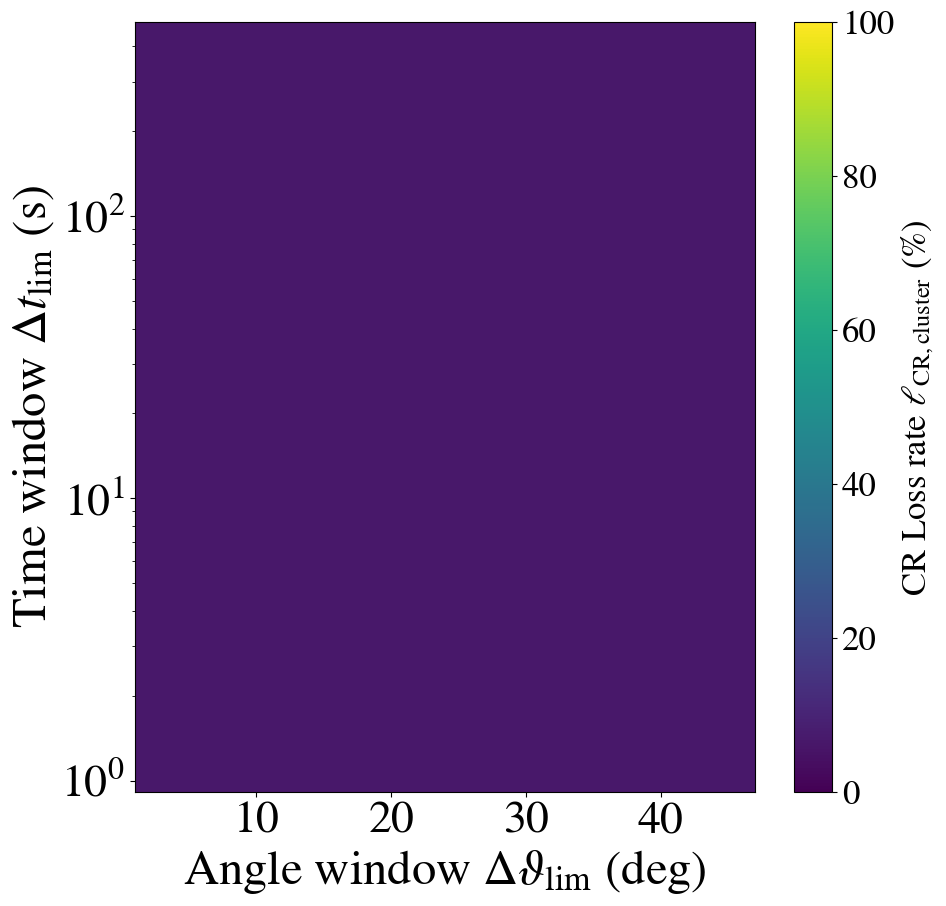

In [42]:

plt.figure(figsize=(10, 10))

X1, Y1 = np.meshgrid(loop_angle_window,#*180/np.pi, 
                     loop_time_window[index_plot_min:index_plot_max]
                     )

im1 = plt.pcolor(X1,
                   Y1,
                   loss_CR_grid_or[index_plot_min:index_plot_max, :], 
                    cmap='viridis', 
                    # aspect='auto',
                    # origin='lower',
                    rasterized=True,
                    norm=mpl.colors.Normalize(
                                                vmin=0,
                                                #  vmax=100,
                                                vmax=loss_CR_grid_or[index_plot_min:index_plot_max, :].max()
                                                ),
                    )

CS = plt.contour(X1,
                   Y1,
                   loss_CR_grid_or[index_plot_min:index_plot_max, :], 
              np.array([2, 3, 4, 6]), 
              colors='white', 
            #   origin='lower', 
            #   extent=extent
              )
plt.clabel(CS, 
           fontsize=30,
           fmt=fmt
           )

# # Loop over data dimensions and create text annotations.
# for i in range(1, len(loop_time_window), 3):
#     for j in range(1, len(loop_angle_window), 3):
#         text = ax[1].text(j, i, 
#                         f"{loss_CR_grid_or[i, j]:.0f}",
#                        ha="center", 
#                        va="center", 
#                        color="black")
        
plt.colorbar(im1, 
            #  ax=ax, 
             label=r'CR Loss rate $\ell_{\rm CR, cluster}$ (%) '
             )

cbar.ax.tick_params(labelsize=30
                    )
cbar.set_label('Cut efficiency (%)', 
               fontsize=38
               )

plt.yscale('log')
plt.xlabel(r'Angle window $\Delta \vartheta_{\rm lim}$ (deg)',
           fontsize=35
           )
plt.xticks([10, 20, 30, 40],)
plt.ylabel(r'Time window $\Delta t_{\rm lim}$ (s)', 
           fontsize=35
           )
plt.tick_params(axis='both', 
                which='major', 
                labelsize=33
                )
plt.grid(False)
# plt.savefig(f"/sps/grand/jlavoisier/code/quantification/0_plots_article/cluster_loss.pdf",
#             format='pdf', 
#             dpi=300, 
#             bbox_inches = "tight"
#             )
plt.show()


In [ ]:


mask_parasite_selected_cluster = np.array([])
for run in RUN:
    mask_parasite_selected_cluster = np.concatenate((mask_parasite_selected_cluster, cluster_selected_pass[run][:len(parasite_selected_time_RUN[run])]))

In [ ]:
mask_parasite_chi2_PWF = parasite_chi2_PWF < chi2_PWF_threshold
mask_parasite_chi2_SWF = parasite_chi2_SWF < chi2_SWF_threshold
mask_parasite_chi2_ADF = parasite_chi2_ADF < chi2_ADF_threshold
mask_parasite_polarization = parasite_polarization < polarization_threshold

mask_parasite_combined = mask_parasite_chi2_PWF & mask_parasite_chi2_SWF & mask_parasite_chi2_ADF & mask_parasite_polarization & np.bool(mask_parasite_selected_cluster)